# Bank Loan Management system

In [20]:
# Import libraries for data handling and numerical calculations
import pandas as pd
import numpy as np

# Import libraries for data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Import function for splitting data into training and testing sets
from sklearn.model_selection import train_test_split

In [21]:
#load dataset
df = pd.read_csv("loan_approval_data (3).csv")
df.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [22]:
print("Dataset Shape:", df.shape)
df.info()

Dataset Shape: (1000, 20)
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str  

In [23]:
print("\nStatistical Summary:")
df.describe()


Statistical Summary:


,Applicant_ID,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,501.220000,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,289.608451,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,1.000000,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,250.250000,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,499.500000,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,752.750000,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,1000.000000,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


In [24]:
#missing values
print(df.isnull().sum())

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64


In [25]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object"]).columns

# Identify numerical columns
numerical_cols = df.select_dtypes(include=["number"]).columns

# Display categorical columns
print("Categorical Columns:")
print(list(categorical_cols))

# Display numerical columns
print("\nNumerical Columns:")
print(list(numerical_cols))

Categorical Columns:
['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved']

Numerical Columns:
['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term']


C:\Users\maana\AppData\Local\Temp\ipykernel_24404\3473939355.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object"]).columns


In [26]:
#check for missing value
missing_value = df.isnull().sum()

print("Missing value in Each Column :- ",missing_value)

Missing value in Each Column :-  Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64


In [27]:
#number of duplicate
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

duplicate_rows = df[df.duplicated()]

print("\nDuplicate Rows:",duplicate_rows)


Number of Duplicate Rows: 0

Duplicate Rows: Empty DataFrame
Columns: [Applicant_ID, Applicant_Income, Coapplicant_Income, Employment_Status, Age, Marital_Status, Dependents, Credit_Score, Existing_Loans, DTI_Ratio, Savings, Collateral_Value, Loan_Amount, Loan_Term, Loan_Purpose, Property_Area, Education_Level, Gender, Employer_Category, Loan_Approved]
Index: []


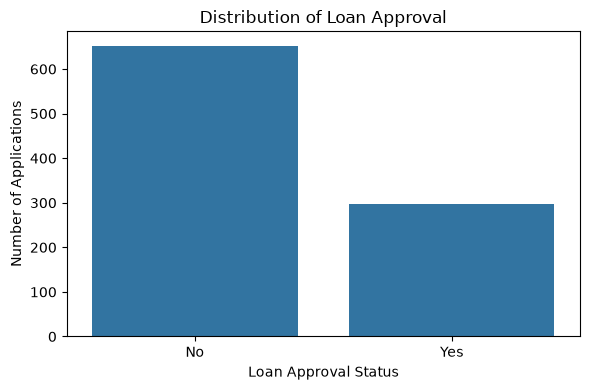

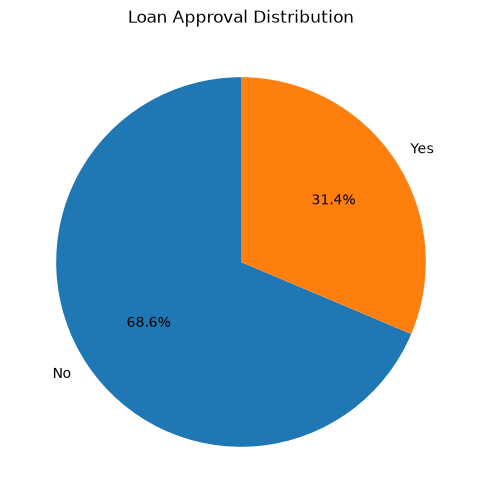

In [28]:
approval_counts = df["Loan_Approved"].value_counts()

# Plot the loan approval distribution using a bar graph
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Approved", order=approval_counts.index)
plt.title("Distribution of Loan Approval")
plt.xlabel("Loan Approval Status")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

# Plot the loan approval distribution using a pie chart
plt.figure(figsize=(6, 6))
plt.pie(
    approval_counts,
    labels=approval_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Loan Approval Distribution")
plt.show()

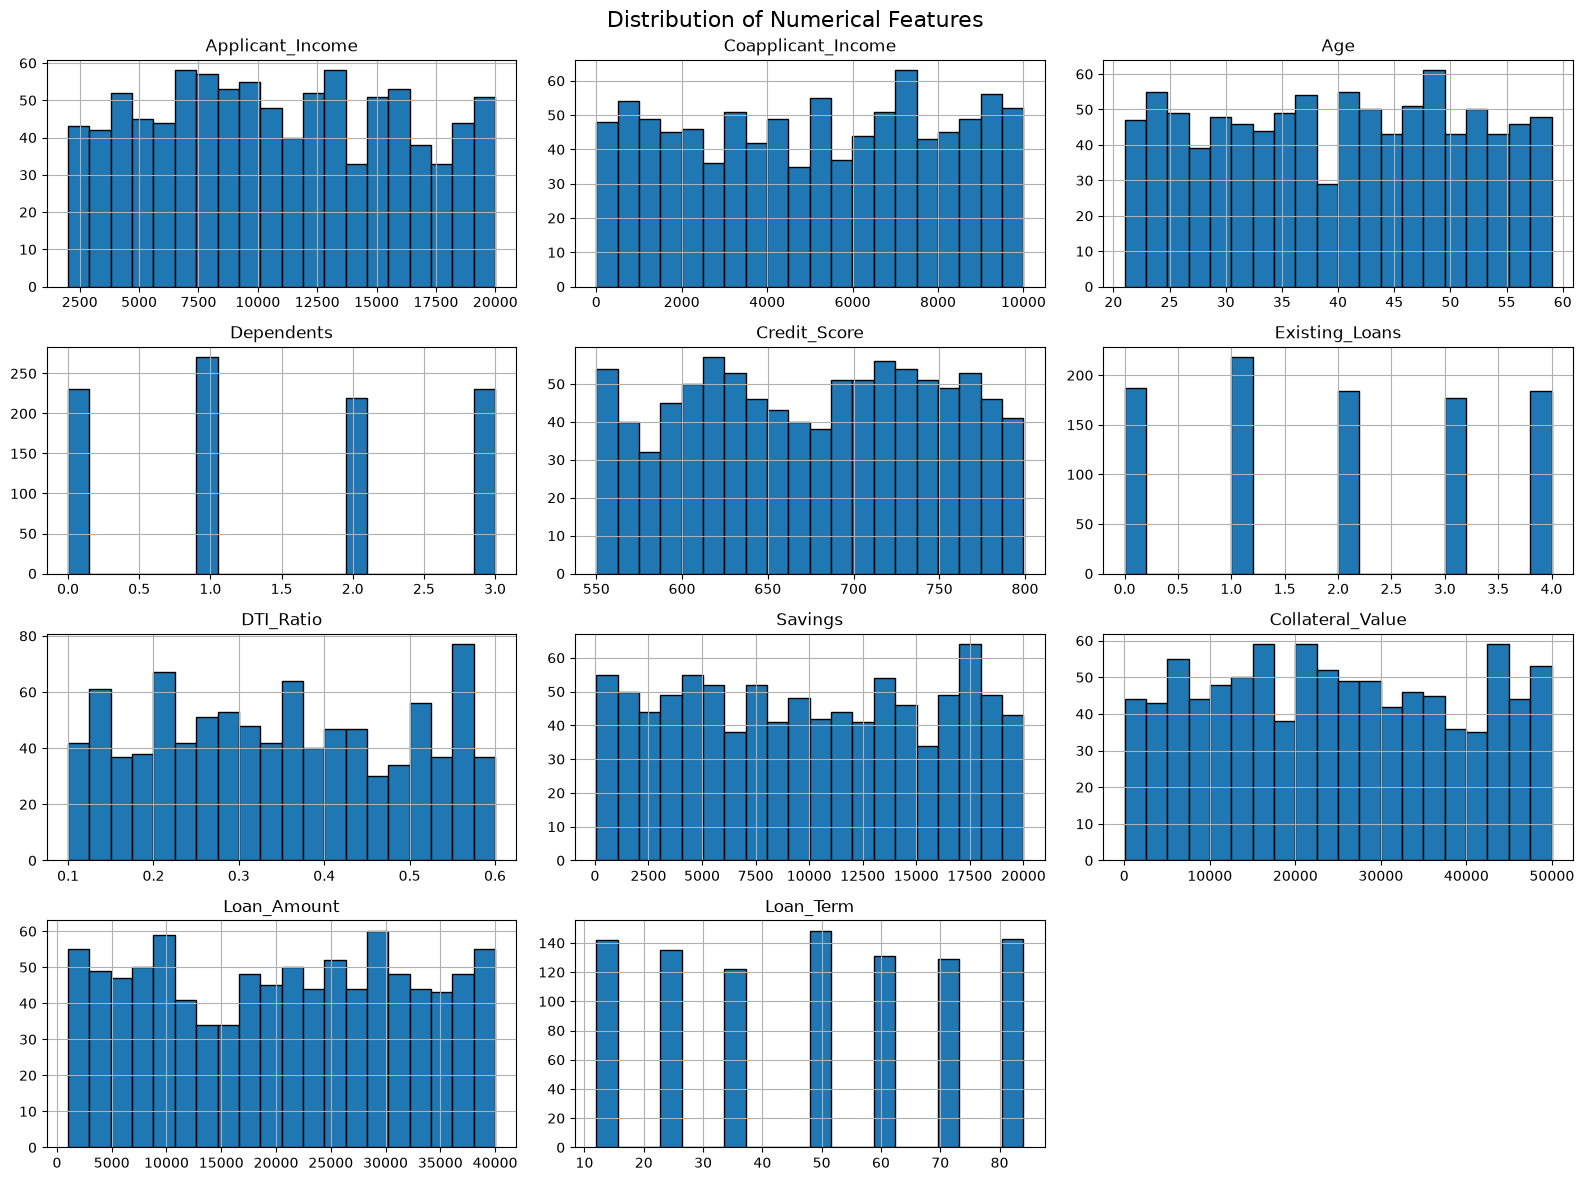

In [29]:
# Select numerical columns, excluding Applicant_ID
numerical_cols = df.select_dtypes(include=["number"]).columns.drop(
    "Applicant_ID", errors="ignore"
)

# Plot histograms for numerical features
df[numerical_cols].hist(figsize=(16, 12), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

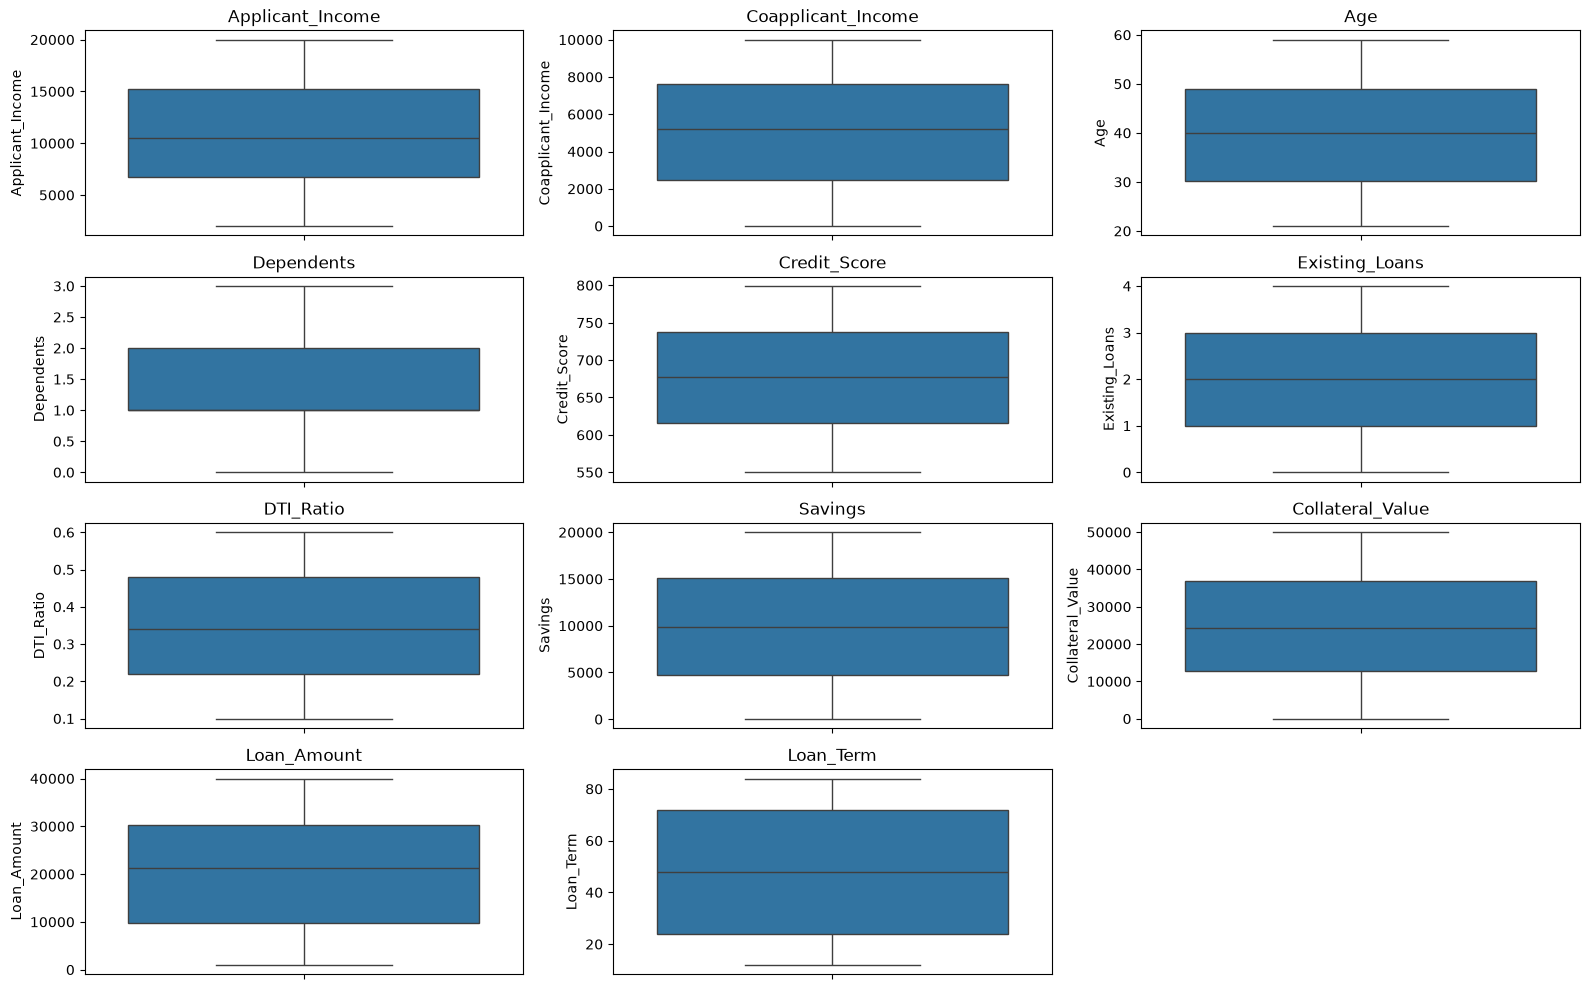

In [30]:
# Select numerical columns, excluding Applicant_ID
numerical_cols = df.select_dtypes(include=["number"]).columns.drop(
    "Applicant_ID", errors="ignore"
)

# Create box plots for numerical features
plt.figure(figsize=(16, 10))

for i, column in enumerate(numerical_cols, 1):
    plt.subplot((len(numerical_cols) + 2) // 3, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

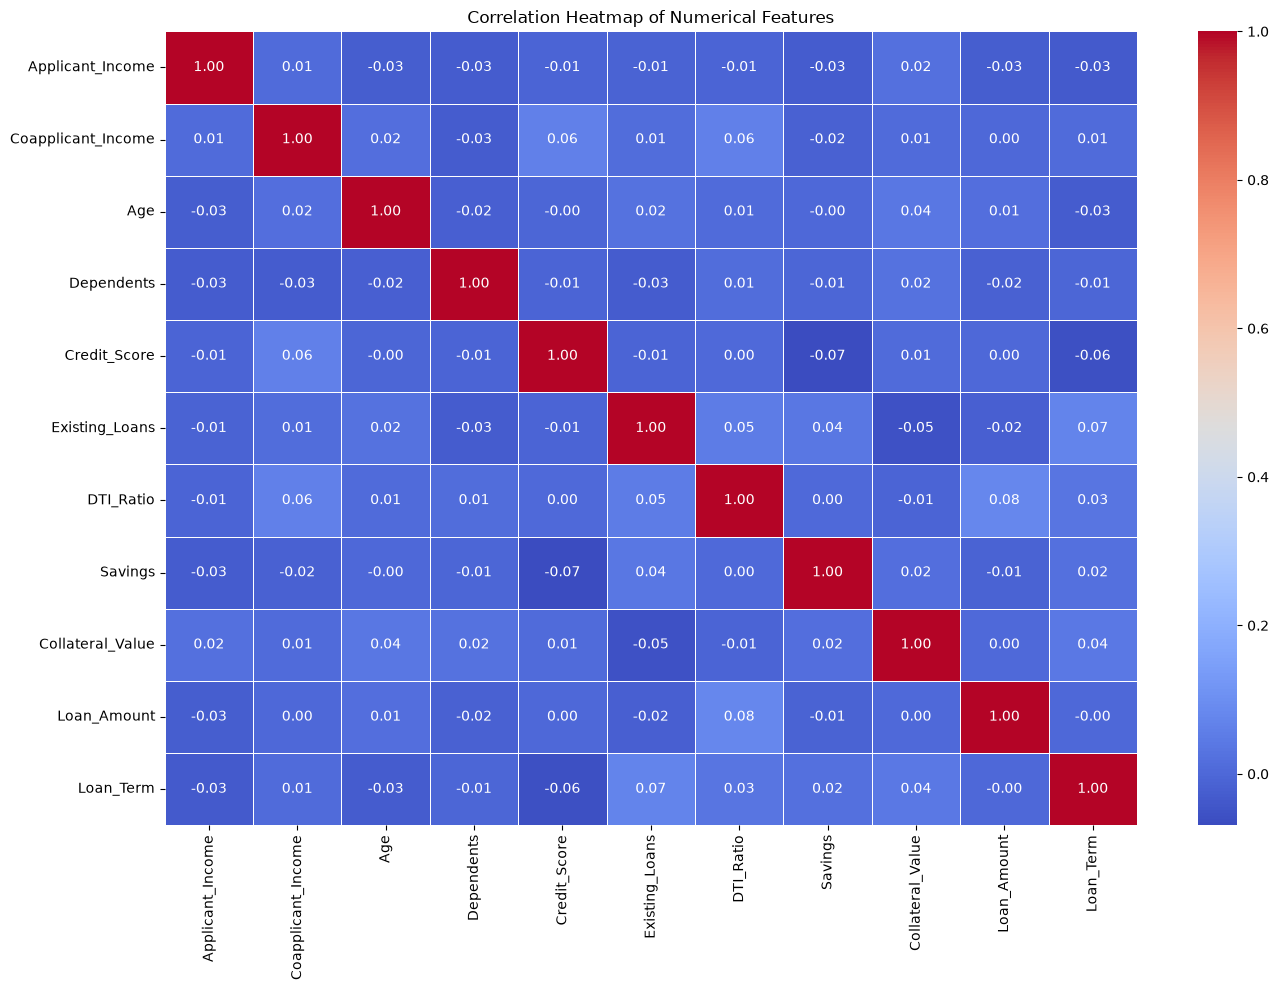

In [31]:

#correlation matrix
correlation_matrix = df[numerical_cols].corr()

# heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

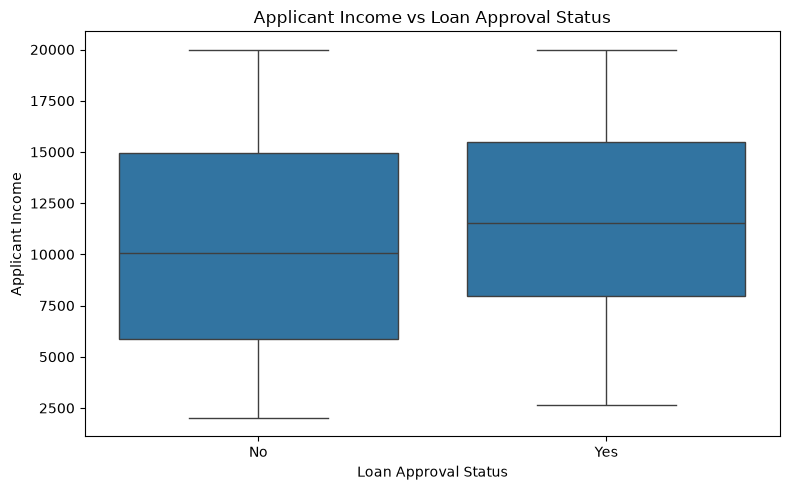

In [32]:
# box plot comparing applicant income by approval status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

plt.title("Applicant Income vs Loan Approval Status")
plt.xlabel("Loan Approval Status")
plt.ylabel("Applicant Income")

plt.tight_layout()
plt.show()

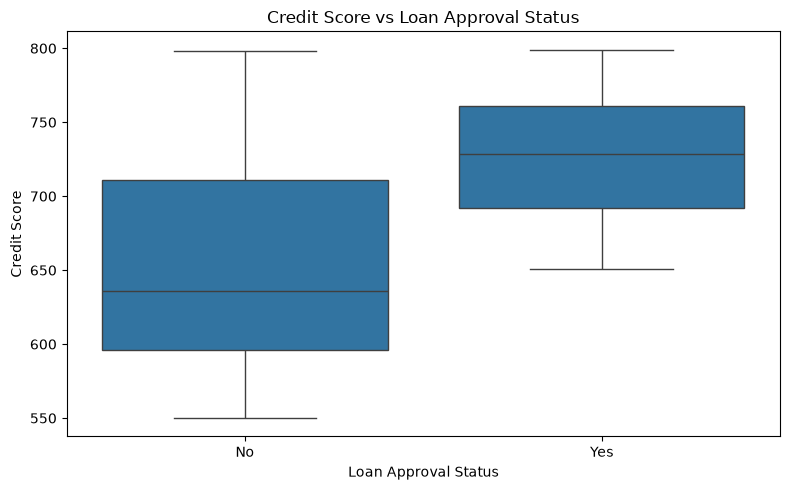

In [33]:
#box plot comparing credit scores by approval status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Credit_Score"
)

plt.title("Credit Score vs Loan Approval Status")
plt.xlabel("Loan Approval Status")
plt.ylabel("Credit Score")

plt.tight_layout()
plt.show()

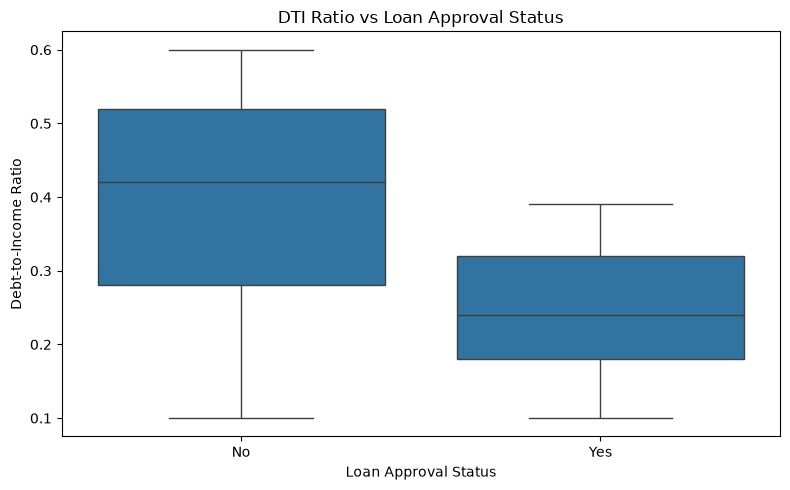

In [34]:
#box plot comparing DTI ratios by approval status
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="DTI_Ratio"
)

plt.title("DTI Ratio vs Loan Approval Status")
plt.xlabel("Loan Approval Status")
plt.ylabel("Debt-to-Income Ratio")

plt.tight_layout()
plt.show()

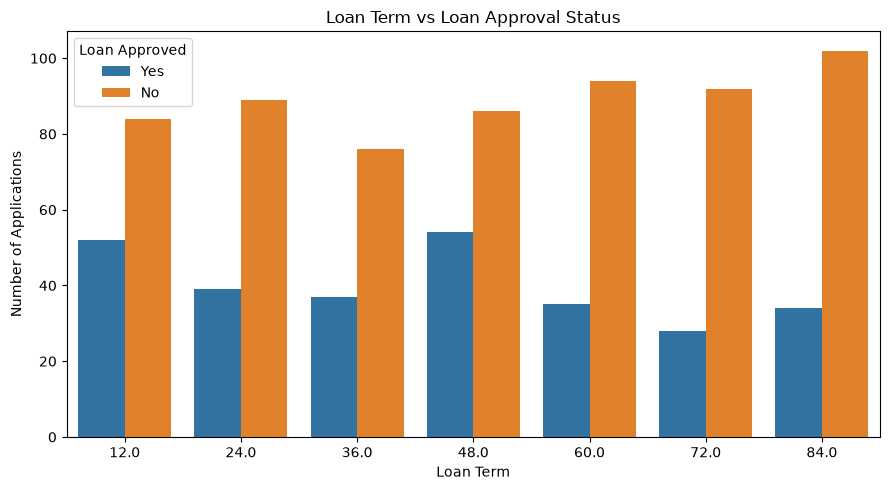

In [35]:
# Create a count plot comparing loan terms by approval status
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Loan_Term",
    hue="Loan_Approved"
)

plt.title("Loan Term vs Loan Approval Status")
plt.xlabel("Loan Term")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

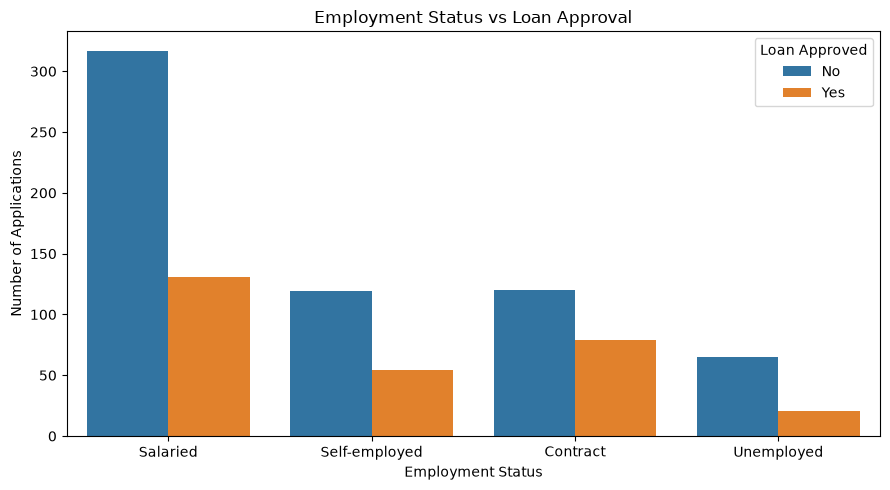

In [36]:
# Create a count plot comparing employment status and loan approval
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Employment_Status",
    hue="Loan_Approved"
)

plt.title("Employment Status vs Loan Approval")
plt.xlabel("Employment Status")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

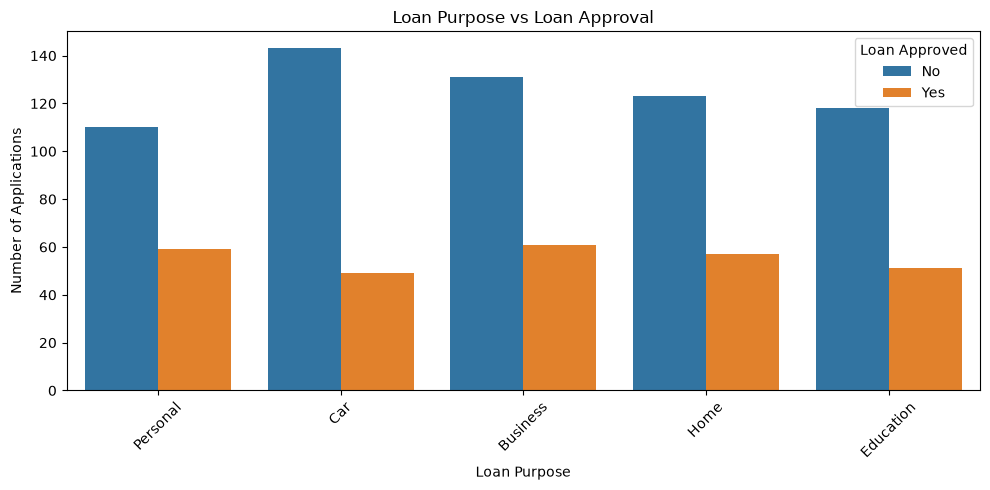

In [37]:
# Create a count plot comparing loan purpose and loan approval
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Loan_Purpose",
    hue="Loan_Approved"
)

plt.title("Loan Purpose vs Loan Approval")
plt.xlabel("Loan Purpose")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45)
plt.legend(title="Loan Approved")

plt.tight_layout()
plt.show()

In [38]:
# Check missing values in input features
print("Missing Values in Features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

# Check total missing values in input features
print("\nTotal Missing Values in X:", X.isnull().sum().sum())

# Check missing values in target
print("\nMissing Values in Target:", y.isnull().sum())

Missing Values in Features:


NameError: name 'X' is not defined

In [ ]:
# Remove Applicant_ID because it is only an identifier
df = df.drop(columns=["Applicant_ID"], errors="ignore")

# Separate input features and target variable
X = df.drop(columns=["Loan_Approved"])
y = df["Loan_Approved"]

# Display the feature and target information
print("Feature Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Distribution:")
print(y.value_counts())

Feature Shape: (1000, 18)
Target Shape: (1000,)

Input Features:
['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age', 'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']

Target Distribution:
Loan_Approved
No     652
Yes    298
Name: count, dtype: int64


In [ ]:
# Check missing values in X and y
print("Missing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

# Check rows with missing target values
print("\nRows with missing target:")
print(df[df["Loan_Approved"].isnull()])

Missing values in X: 900
Missing values in y: 50

Rows with missing target:
     Applicant_Income  Coapplicant_Income Employment_Status   Age  \
15             7311.0              1301.0          Salaried  42.0   
26            19912.0              5796.0          Contract  28.0   
100            8910.0              6960.0     Self-employed  23.0   
122            5627.0              8044.0     Self-employed  30.0   
191           11208.0              1165.0          Salaried  43.0   
195            4049.0               145.0          Salaried  47.0   
263            2190.0              5295.0          Contract  49.0   
290           18921.0              2604.0     Self-employed  23.0   
293           10716.0              3738.0     Self-employed  38.0   
310               NaN               294.0          Salaried  39.0   
312               NaN              9882.0          Contract  25.0   
314            5051.0              2064.0          Contract  50.0   
324            6465.0      

In [ ]:
# Remove rows where the target variable is missing
df = df.dropna(subset=["Loan_Approved"]).copy()

# Separate features and target again
X = df.drop(columns=["Loan_Approved", "Applicant_ID"], errors="ignore")
y = df["Loan_Approved"]

# Verify the result
print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isnull().sum())

Feature shape: (950, 18)
Target shape: (950,)
Missing target values: 0


In [ ]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (760, 18)
Testing Features: (190, 18)

Training Target: (760,)
Testing Target: (190,)


In [ ]:
# Import preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Create an imputer for numerical features
numerical_imputer = SimpleImputer(strategy="median")

# Create an imputer for categorical features
categorical_imputer = SimpleImputer(strategy="most_frequent")

# Create preprocessing pipelines
numerical_pipeline = Pipeline(steps=[
    ("imputer", numerical_imputer),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", categorical_imputer),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Numerical preprocessing: Median Imputation + Standard Scaling")
print("Categorical preprocessing: Most-Frequent Imputation + One-Hot Encoding")
print("\nPreprocessing pipeline created successfully!")

Numerical preprocessing: Median Imputation + Standard Scaling
Categorical preprocessing: Most-Frequent Imputation + One-Hot Encoding

Preprocessing pipeline created successfully!


In [ ]:
# Fit the preprocessing pipeline on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessing pipeline
X_test_processed = preprocessor.transform(X_test)

# Display the shapes of the processed datasets
print("Original Training Shape:", X_train.shape)
print("Processed Training Shape:", X_train_processed.shape)

print("\nOriginal Testing Shape:", X_test.shape)
print("Processed Testing Shape:", X_test_processed.shape)

# Check for remaining missing values
print("\nMissing Values in Processed Training Data:",
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray")
               else X_train_processed).sum())

Original Training Shape: (760, 18)
Processed Training Shape: (760, 34)

Original Testing Shape: (190, 18)
Processed Testing Shape: (190, 34)

Missing Values in Processed Training Data: 0


In [ ]:
## featuring engineerng
# Create a copy of the training and testing datasets
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

# Create Total Income feature
X_train_fe["Total_Income"] = (
    X_train_fe["Applicant_Income"] +
    X_train_fe["Coapplicant_Income"]
)

X_test_fe["Total_Income"] = (
    X_test_fe["Applicant_Income"] +
    X_test_fe["Coapplicant_Income"]
)

# Create Loan-to-Income Ratio
X_train_fe["Loan_to_Income_Ratio"] = (
    X_train_fe["Loan_Amount"] /
    X_train_fe["Total_Income"].replace(0, np.nan)
)

X_test_fe["Loan_to_Income_Ratio"] = (
    X_test_fe["Loan_Amount"] /
    X_test_fe["Total_Income"].replace(0, np.nan)
)

# Display the new features
print("New Features Created:")
print("1. Total_Income")
print("2. Loan_to_Income_Ratio")

print("\nTraining Data Shape Before Feature Engineering:", X_train.shape)
print("Training Data Shape After Feature Engineering:", X_train_fe.shape)

print("\nSample of Engineered Features:")
print(
    X_train_fe[
        ["Applicant_Income", "Coapplicant_Income",
         "Total_Income", "Loan_Amount", "Loan_to_Income_Ratio"]
    ].head()
)

New Features Created:
1. Total_Income
2. Loan_to_Income_Ratio

Training Data Shape Before Feature Engineering: (760, 18)
Training Data Shape After Feature Engineering: (760, 20)

Sample of Engineered Features:
     Applicant_Income  Coapplicant_Income  Total_Income  Loan_Amount  \
443            7486.0              9127.0       16613.0      36198.0   
212            7592.0              8202.0       15794.0      13204.0   
365           16069.0              3155.0       19224.0      29016.0   
783            7256.0              9654.0       16910.0      38981.0   
667           17745.0                 NaN           NaN       8641.0   

     Loan_to_Income_Ratio  
443              2.178896  
212              0.836014  
365              1.509363  
783              2.305204  
667                   NaN  


In [ ]:
# Identify numerical features after feature engineering
numerical_features = X_train_fe.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features after feature engineering
categorical_features = X_train_fe.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Create the numerical preprocessing pipeline
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create the categorical preprocessing pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

# Fit preprocessing on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train_fe)

# Transform testing data using the same fitted pipeline
X_test_processed = preprocessor.transform(X_test_fe)

# Display the results
print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nTraining Data Before Preprocessing:", X_train_fe.shape)
print("Training Data After Preprocessing:", X_train_processed.shape)

print("\nTesting Data Before Preprocessing:", X_test_fe.shape)
print("Testing Data After Preprocessing:", X_test_processed.shape)

print("\nPreprocessing Completed Successfully!")

Numerical Features: 13
Categorical Features: 7

Training Data Before Preprocessing: (760, 20)
Training Data After Preprocessing: (760, 36)

Testing Data Before Preprocessing: (190, 20)
Testing Data After Preprocessing: (190, 36)

Preprocessing Completed Successfully!


In [ ]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {lr_accuracy:.4f}")
print(f"Accuracy Percentage: {lr_accuracy * 100:.2f}%")

Logistic Regression Accuracy: 0.8895
Accuracy Percentage: 88.95%


In [ ]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_processed, y_train)

# Predict loan approval on testing data
y_pred_lr = lr_model.predict(X_test_processed)

# Calculate model accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Display results
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))



Logistic Regression Accuracy: 88.95 %

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.92      0.92       130
         Yes       0.83      0.82      0.82        60

    accuracy                           0.89       190
   macro avg       0.87      0.87      0.87       190
weighted avg       0.89      0.89      0.89       190


Confusion Matrix:
[[120  10]
 [ 11  49]]


In [ ]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, pos_label="Yes", zero_division=0)

# Display results in a simple format
print("Logistic Regression Results")
print("----------------------------")
print(f"Accuracy  : {lr_accuracy * 100:.2f}%")
print(f"Precision : {lr_precision * 100:.2f}%")
print(f"Recall    : {lr_recall * 100:.2f}%")
print(f"F1-Score  : {lr_f1 * 100:.2f}%")

Logistic Regression Results
----------------------------
Accuracy  : 88.95%
Precision : 83.05%
Recall    : 81.67%
F1-Score  : 82.35%


In [ ]:
# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train)

# Predict loan approval on testing data
y_pred_dt = dt_model.predict(X_test_processed)

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, pos_label="Yes", zero_division=0)

# Display results
print("Decision Tree Results")
print("---------------------")
print(f"Accuracy  : {dt_accuracy * 100:.2f}%")
print(f"Precision : {dt_precision * 100:.2f}%")
print(f"Recall    : {dt_recall * 100:.2f}%")
print(f"F1-Score  : {dt_f1 * 100:.2f}%")

Decision Tree Results
---------------------
Accuracy  : 93.68%
Precision : 88.71%
Recall    : 91.67%
F1-Score  : 90.16%


In [ ]:
# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Predict loan approval on testing data
y_pred_rf = rf_model.predict(X_test_processed)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes", zero_division=0)

# Display results
print("Random Forest Results")
print("---------------------")
print(f"Accuracy  : {rf_accuracy * 100:.2f}%")
print(f"Precision : {rf_precision * 100:.2f}%")
print(f"Recall    : {rf_recall * 100:.2f}%")
print(f"F1-Score  : {rf_f1 * 100:.2f}%")

Random Forest Results
---------------------
Accuracy  : 94.21%
Precision : 91.53%
Recall    : 90.00%
F1-Score  : 90.76%


In [ ]:
# Convert loan approval labels into numerical values
y_train_xgb = y_train.map({"No": 0, "Yes": 1})
y_test_xgb = y_test.map({"No": 0, "Yes": 1})

# Check the encoded labels
print("Training Target Labels:")
print(y_train_xgb.value_counts())

print("\nTesting Target Labels:")
print(y_test_xgb.value_counts())

Training Target Labels:
Loan_Approved
0    522
1    238
Name: count, dtype: int64

Testing Target Labels:
Loan_Approved
0    130
1     60
Name: count, dtype: int64


In [ ]:
# Import XGBoost Classifier
from xgboost import XGBClassifier

# Create the XGBoost model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric="logloss"
)

# Train the model using encoded target labels
xgb_model.fit(X_train_processed, y_train_xgb)

# Predict loan approval on testing data
y_pred_xgb = xgb_model.predict(X_test_processed)

# Convert predictions back to Yes and No
y_pred_xgb = pd.Series(y_pred_xgb).map({0: "No", 1: "Yes"})

# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)
xgb_recall = recall_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)
xgb_f1 = f1_score(
    y_test, y_pred_xgb, pos_label="Yes", zero_division=0
)

# Display results
print("XGBoost Results")
print("----------------")
print(f"Accuracy  : {xgb_accuracy * 100:.2f}%")
print(f"Precision : {xgb_precision * 100:.2f}%")
print(f"Recall    : {xgb_recall * 100:.2f}%")
print(f"F1-Score  : {xgb_f1 * 100:.2f}%")

XGBoost Results
----------------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [ ]:
# Import evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Store predictions from all four models
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb
}

# Create a dictionary to store model results
model_results = {}

# Calculate metrics for each model
for model_name, predictions in model_predictions.items():

    model_results[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "Precision": precision_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100,
        "Recall": recall_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100,
        "F1-Score": f1_score(
            y_test, predictions, pos_label="Yes", zero_division=0
        ) * 100
    }

# Display results
for model_name, metrics in model_results.items():
    print(f"\n{model_name}")
    print("-" * len(model_name))
    print(f"Accuracy  : {metrics['Accuracy']:.2f}%")
    print(f"Precision : {metrics['Precision']:.2f}%")
    print(f"Recall    : {metrics['Recall']:.2f}%")
    print(f"F1-Score  : {metrics['F1-Score']:.2f}%")


Logistic Regression
-------------------
Accuracy  : 88.95%
Precision : 83.05%
Recall    : 81.67%
F1-Score  : 82.35%

Decision Tree
-------------
Accuracy  : 93.68%
Precision : 88.71%
Recall    : 91.67%
F1-Score  : 90.16%

Random Forest
-------------
Accuracy  : 94.21%
Precision : 91.53%
Recall    : 90.00%
F1-Score  : 90.76%

XGBoost
-------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [ ]:
# Find the model with the highest F1-score
best_model_name = max(
    model_results,
    key=lambda model: model_results[model]["F1-Score"]
)

# Display the best model
print("Best Performing Model:", best_model_name)
print("-" * 40)

# Display its evaluation metrics
best_metrics = model_results[best_model_name]

print(f"Accuracy  : {best_metrics['Accuracy']:.2f}%")
print(f"Precision : {best_metrics['Precision']:.2f}%")
print(f"Recall    : {best_metrics['Recall']:.2f}%")
print(f"F1-Score  : {best_metrics['F1-Score']:.2f}%")

Best Performing Model: XGBoost
----------------------------------------
Accuracy  : 95.26%
Precision : 89.23%
Recall    : 96.67%
F1-Score  : 92.80%


In [ ]:
# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest
feature_importance = rf_model.feature_importances_

# Create a DataFrame of feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 10 most important features
print("Top 10 Important Features")
print("-------------------------")

for _, row in importance_df.head(10).iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f}")

Top 10 Important Features
-------------------------
num__Credit_Score: 0.3296
num__DTI_Ratio: 0.3258
num__Applicant_Income: 0.0543
num__Loan_to_Income_Ratio: 0.0413
num__Loan_Amount: 0.0406
num__Total_Income: 0.0345
num__Collateral_Value: 0.0271
num__Savings: 0.0213
num__Coapplicant_Income: 0.0191
num__Loan_Term: 0.0189


In [ ]:
# Import joblib for saving machine learning models
import joblib

# Select the best model
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model
}

best_model = models[best_model_name]

# Save the best model
joblib.dump(best_model, "best_loan_approval_model.pkl")

# Save the preprocessing pipeline
joblib.dump(preprocessor, "loan_preprocessor.pkl")

# Display confirmation
print("Best Model:", best_model_name)
print("Model saved as: best_loan_approval_model.pkl")
print("Preprocessor saved as: loan_preprocessor.pkl")
print("\nModel and preprocessing pipeline saved successfully!")

Best Model: XGBoost
Model saved as: best_loan_approval_model.pkl
Preprocessor saved as: loan_preprocessor.pkl

Model and preprocessing pipeline saved successfully!


In [40]:
# Import pandas
import pandas as pd

# Create a function to predict loan approval
def predict_loan_approval(applicant_data):

    # Convert applicant details into a DataFrame
    applicant_df = pd.DataFrame([applicant_data])

    # Remove Applicant_ID if provided
    applicant_df = applicant_df.drop(
        columns=["Applicant_ID"],
        errors="ignore"
    )

    # Create engineered features
    applicant_df["Total_Income"] = (
        applicant_df["Applicant_Income"] +
        applicant_df["Coapplicant_Income"]
    )

    # Calculate Loan-to-Income Ratio
    applicant_df["Loan_to_Income_Ratio"] = (
        applicant_df["Loan_Amount"] /
        applicant_df["Total_Income"].replace(0, float("nan"))
    )

    # Apply the fitted preprocessing pipeline
    applicant_processed = preprocessor.transform(applicant_df)

    # Predict loan approval
    prediction = best_model.predict(applicant_processed)[0]

    # Convert prediction into a readable result
    if prediction in [1, "1", True, "Yes", "yes"]:
        result = "Loan Approved"
    else:
        result = "Loan Rejected"

    # Display the prediction
    print("Loan Approval Prediction")
    print("------------------------")
    print("Result:", result)

    return result

In [42]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("y_train exists:", "y_train" in globals())
print("y_test exists:", "y_test" in globals())
print("preprocessor exists:", "preprocessor" in globals())
print("best_model exists:", "best_model" in globals())

X_train exists: False
X_test exists: False
y_train exists: False
y_test exists: False
preprocessor exists: False
best_model exists: False
